In [4]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import sklearn as sk
from datetime import date
from pandas.plotting import lag_plot
import statsmodels.api as sm

start = '1992-01-01'
end = date.today().isoformat()
# linearity: verifying that there is a linear relationship between the
# variables

# independence: verifying that each error doesn't relate to the 
# previous one (autocorrelation); autocorrelation = bad

# Homoscedasticity: verifying that, essentially, the residuals don't
# go through an obvious behavior change in the middle of the study

# Normality: Distribution of residuals follows a bell curve 
# (is normal; statistics)

[*********************100%***********************]  1 of 1 completed


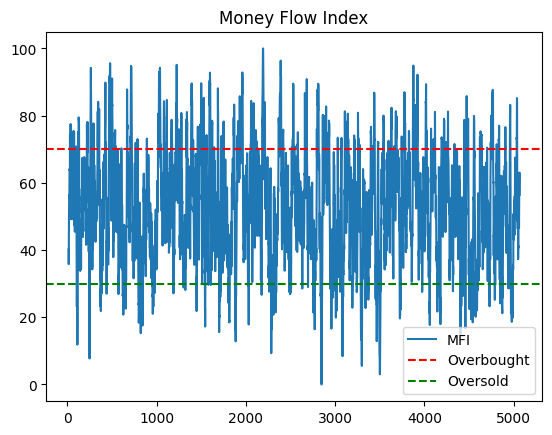

                            OLS Regression Results                            
Dep. Variable:      1 Period % Change   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.323
Date:                Tue, 03 Mar 2026   Prob (F-statistic):              0.265
Time:                        19:16:12   Log-Likelihood:                 21264.
No. Observations:                5022   AIC:                        -4.252e+04
Df Residuals:                    5018   BIC:                        -4.249e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0002      0.000     -0.655      0.5

Price,Adj Close,Close,High,Low,Open,Volume,Typical_Price,Raw_Money_Flow,Price_Change,Pos_Flow,...,BB_SMA,BB_STD,Upper_Band,Lower_Band,BB,RSI,Close + 1,1 Period % Change,Predictions,Residuals
0,411.902496,411.902496,412.119995,411.095001,411.410004,7173187,411.705831,2.953243e+09,0.622498,2.953243e+09,...,410.180997,1.128764,412.438524,407.923470,0.118720,53.272399,413.137512,0.002998,0.000036,-0.002962
1,413.137512,413.137512,413.440002,411.770905,411.910004,8754863,412.782806,3.613857e+09,1.076976,3.613857e+09,...,410.401372,1.253886,412.909143,407.893600,-0.045532,56.892205,413.584991,0.001083,0.000036,-0.001047
2,413.584991,413.584991,413.789886,412.940002,413.130005,12894009,413.438293,5.330877e+09,0.655487,5.330877e+09,...,410.597371,1.427129,413.451629,407.743113,-0.023362,57.966283,413.459991,-0.000302,0.000112,0.000414
3,413.459991,413.459991,413.839996,413.130005,413.589996,15617876,413.476664,6.457627e+09,0.038371,6.457627e+09,...,410.770120,1.555028,413.880175,407.660065,0.067552,62.372392,412.338409,-0.002713,0.000188,0.002900
4,412.338409,412.338409,415.089996,412.140015,412.809998,18111203,413.189473,7.483358e+09,-0.287191,0.000000e+00,...,410.895541,1.576224,414.047990,407.743093,0.271151,52.659452,411.579987,-0.001839,0.000243,0.002082
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5018,678.320007,678.320007,678.489990,674.659973,676.000000,10581256,677.156657,7.165168e+09,3.029968,7.165168e+09,...,684.194156,4.681728,693.557612,674.830699,0.813674,42.746805,679.820007,0.002211,0.000202,-0.002009
5019,679.820007,679.820007,680.429993,676.080017,678.320007,7605785,678.776672,5.162629e+09,1.620015,5.162629e+09,...,683.754657,4.657893,693.070444,674.438870,0.711182,45.179319,680.500000,0.001000,0.000143,-0.000857
5020,680.500000,680.500000,681.909973,679.664978,679.820007,9358641,680.691650,6.370349e+09,1.914978,6.370349e+09,...,683.346408,4.561692,692.469792,674.223024,0.655995,46.288366,681.049988,0.000808,0.000170,-0.000638
5021,681.049988,681.049988,682.609985,679.275024,680.500000,11491316,680.978333,7.825337e+09,0.286682,7.825337e+09,...,682.932907,4.362168,691.657242,674.208572,0.607912,44.369934,680.280029,-0.001131,0.000198,0.001328


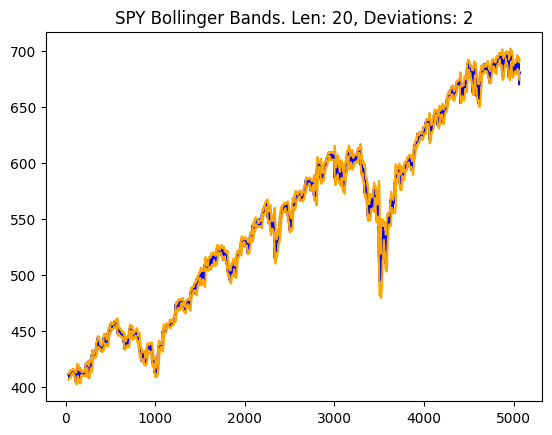

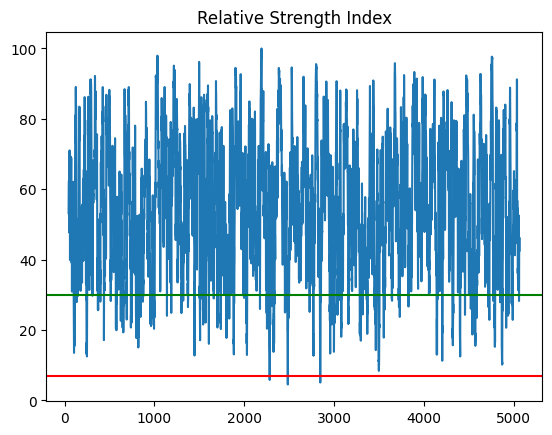

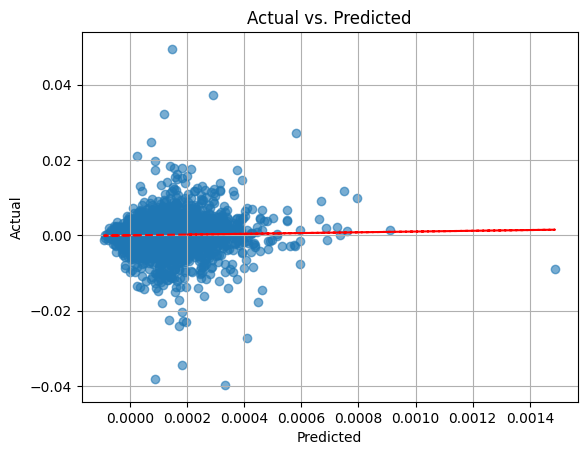

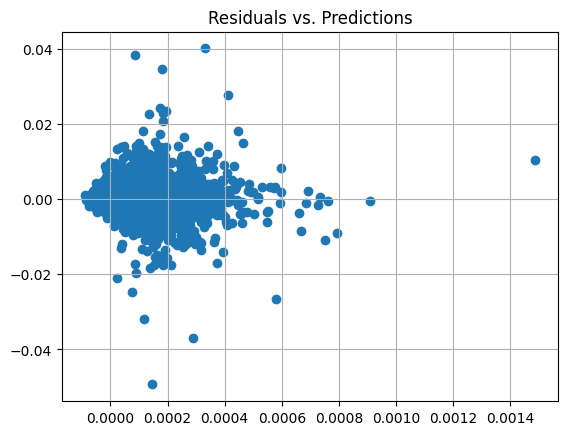

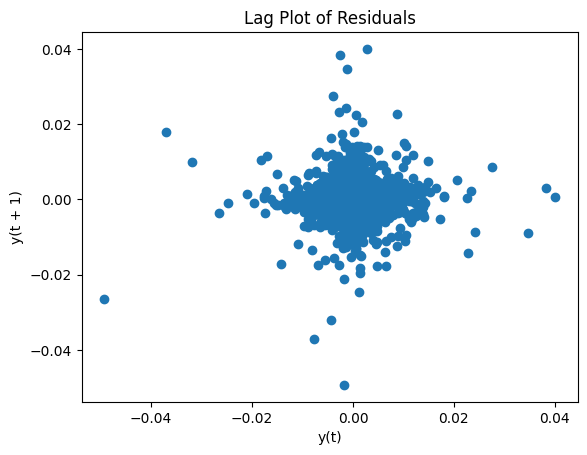

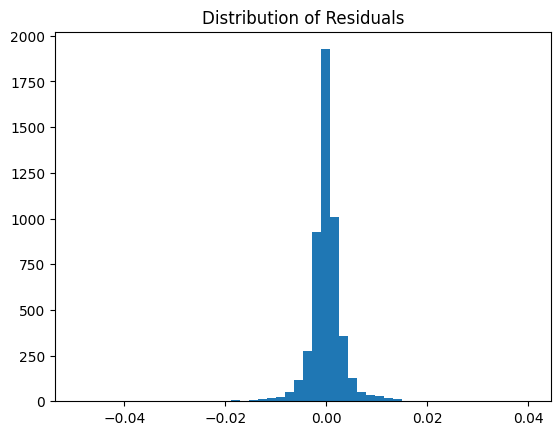

In [5]:
TICKER = 'SPY'
INTERVAL='1h'

# set period based on interval
if INTERVAL == '1h':
    PERIOD = '730d'
else:
    PERIOD = 'max'

SHIFT = 1
MACD_FAST = 12
MACD_SLOW = 27
MACD_SPAN = 9
MFI_LENGTH = 14
MFI_OVERBOUGHT = 70
MFI_OVERSOLD = 30
RSI_LENGTH = 14
RSI_OVERBOUGHT = 7
RSI_OVERSOLD = 30
BB_LEN = 20
DEVS = 2

# what subsetion of that data are you interested in
LOOKBACK = 10000

#potential variables:
#interest rates
#global trade tensions
#consumer sentiment
#oil outlook
#general macroeconomic data (inflation, job market, etc)
#may operate across a larger time scale
STRATEGY = ['Volume', 'MFI', 'BB']

def get_data(ticker=TICKER, lookback=LOOKBACK, interval=INTERVAL):

    # get data at interval you want
    df = yf.download(ticker, interval=interval, auto_adjust=False, period=PERIOD)
    df.columns = df.columns.get_level_values(0)

    # reset the index to make plots prettier
    df = df.reset_index(drop=True)

    # only return the subset of data you are interested in
    return df.iloc[-lookback:, :]


def bull_fvg(df):

    df['High_2prev'] = df['High'].shift(2)
    df['Bull_FVG'] = (df['Low'] > df['High_2prev']).astype(int)
    df['Bull_FVG_Val'] = (df['Low'] - df['High_2prev']) * df['Bull_FVG'] / df['Close']

    FVGs = df[df['Bull_FVG_Val'] > 0]
    plt.figure()
    plt.hist(FVGs['Bull_FVG_Val'], bins=10)
    plt.title('Bullish Fair Value Gap Values')
    return df

def bear_fvg(df):

    df['Low_2prev'] = df['Low'].shift(2)
    df['Bear_FVG'] = (df['High'] < df['Low_2prev']).astype(int)
    df['Bear_FVG_Val'] = (df['High'] - df['Low_2prev']) * df['Bear_FVG'] / df['Close']

    FVGs = df[df['Bear_FVG_Val'] < 0]
    plt.figure()
    plt.hist(FVGs['Bear_FVG_Val'], bins=10)
    plt.title('Bearish Fair Value Gap Values')
    return df


def both_fvg(df):
    df = df[(df['Bull_FVG'] == 1) | (df['Bear_FVG'] == 1)].copy()
    df['Both_FVG'] = df['Bear_FVG_Val'] + df['Bull_FVG_Val']

    plt.figure()
    plt.hist(df['Both_FVG'])
    plt.title('All FVGs')

    return df



def add_MACD(df, fast=MACD_FAST, slow=MACD_SLOW, span=MACD_SPAN):

    df[f'{fast}_ema'] = df['Close'].ewm(span=fast).mean()
    df[f'{slow}_ema'] = df['Close'].ewm(span=slow).mean()

    # macd line is the difference betweent he fast and slow
    df[f'MACD'] = df[f'{fast}_ema'] - df[f'{slow}_ema']

    # macd signal is a 9-period moving average of this line
    df['Signal'] = df['MACD'].ewm(span=span).mean()

    # MACD histogram is almost always what is used in TA
    df['MACD_hist'] = df['MACD'] - df['Signal']

    # plot the histogram
    plt.figure()
    plt.bar(x=range(len(df)), height=df['MACD_hist'])
    plt.title(f'{MACD_FAST} - {MACD_SLOW} - {MACD_SPAN} MACD Histogram')

    return df

def add_MFI(df, length=MFI_LENGTH, overbought=MFI_OVERBOUGHT, oversold=MFI_OVERSOLD):
    df = df.copy()

    # Step 1: Calculate typical price
    df['Typical_Price'] = (df['High'] + df['Low'] + df['Close']) / 3

    # Step 2: Calculate raw money flow
    df['Raw_Money_Flow'] = df['Typical_Price'] * df['Volume']

    # Step 3: Classify positive/negative money flow
    df['Price_Change'] = df['Typical_Price'].diff()

    df['Pos_Flow'] = np.where(df['Price_Change'] > 0, df['Raw_Money_Flow'], 0)
    df['Neg_Flow'] = np.where(df['Price_Change'] < 0, df['Raw_Money_Flow'], 0)

    # Step 4: Money Flow Ratio and MFI
    pos_sum = df['Pos_Flow'].rolling(window=length).sum()
    neg_sum = df['Neg_Flow'].rolling(window=length).sum()
    mfr = pos_sum / neg_sum
    df['MFI'] = 100 - (100 / (1 + mfr))

    # Step 5: Plot
    plt.figure()
    plt.plot(df['MFI'], label='MFI')
    plt.axhline(overbought, color='red', linestyle='--', label='Overbought')
    plt.axhline(oversold, color='green', linestyle='--', label='Oversold')
    plt.title('Money Flow Index')
    plt.legend()
    plt.show()

    return df.dropna()

def add_BB(df, devs=DEVS, bb_len=BB_LEN):

    # can change to ema (use MACD video/code for reference)
    df['BB_SMA'] = df['Close'].rolling(bb_len).mean()

    # get the standard deviation of the close prices for the period
    df['BB_STD'] = df['Close'].rolling(bb_len).std()

    df['Upper_Band'] = df['BB_SMA'] + (devs * df['BB_STD'])
    df['Lower_Band'] = df['BB_SMA'] - (devs * df['BB_STD'])

    df['BB'] = (df['Upper_Band'] - df['Close']) / (df['Upper_Band'] - df['Lower_Band'])

    df = df.dropna()

    plt.figure()
    plt.plot(df['Close'], color='blue')
    plt.plot(df['Upper_Band'], color='orange')
    plt.plot(df['Lower_Band'], color='orange')
    plt.title(f'{TICKER} Bollinger Bands. Len: {BB_LEN}, Deviations: {DEVS}');

    return df

def add_RSI(df, length=RSI_LENGTH, overbought=RSI_OVERBOUGHT, oversold=RSI_OVERSOLD):

    price_change = df['Close'].diff()
    
    # separate gains/losses
    gain = price_change.where(price_change > 0, 0)
    loss = -price_change.where(price_change < 0, 0)

    # average gain vs loss
    avg_gain = gain.rolling(window=length).mean()
    avg_loss = loss.rolling(window=length).mean()

    # calculate rsi
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    df['RSI'] = rsi

    # plot the relative strength index
    plt.figure()
    plt.plot(df['RSI'])
    plt.axhline(overbought, color='red')
    plt.axhline(oversold, color='green')
    plt.title('Relative Strength Index')

    return df.dropna()

# define the target variable (also called dependent variable, or y)
def add_target(df, shift=SHIFT, interval=SHIFT):

    # what is the close price SHIFT days from now?
    df[f'Close + {shift}'] = df['Close'].shift(-shift)

    # what is the change in close price SHIFT days from now?
    df[f'{shift} Period % Change'] = (df[f'Close + {shift}'] - df['Close']) / df['Close']
    
    # fix autocorrelation within target
    df = df.iloc[::interval].reset_index(drop=True)

    return df

#this gets rid of autocorrelation when we shift multiple days
def fix_autocorrelation(df, interval=SHIFT):

    print(f"#rows before autocorrelation fix: {len(df)}")
    df = df.iloc[::interval].reset_index(drop=True)
    print(f"#rows after autocorrelation fix: {len(df)}")

    return df



def generate_regression_output(df, features=STRATEGY, target=f'{SHIFT} Period % Change'):
    subset = df[features + [target]].dropna()

    X = subset[features]
    y = subset[target]

    X_with_const = sm.add_constant(X)
    model = sm.OLS(y, X_with_const).fit()

    intercept = model.params['const']
    coefficients = model.params.drop('const')
    r2 = model.rsquared
    p_values = model.pvalues.drop('const')
    model_p_value = model.f_pvalue  #probability that relationship is not statistically significant
    n_obs = len(subset)

    y_pred = model.predict(X_with_const)

    #Console summary
    #R squared is what we are looking for to actually determine if there is a relationship or not
    # (> .1 -> possible weak relationship; > .6 -> possible relationship)
    print(model.summary())

    # Plot actual vs predicted
    plt.figure()
    plt.scatter(y_pred, y, alpha=0.6)
    plt.plot(y_pred, y_pred, color='red', linestyle='--')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Actual vs. Predicted")
    plt.grid(True)

    return df, intercept, coefficients, model_p_value


#determine if regression analysis is valid or not by testing:
#   linearity, homoscedasticity, independence, and normality
def validate_regression_output(df, coef, intercept):
    df['Predictions'] = intercept
    for feature in coef.index:
        df['Predictions'] += df[feature] * coef[feature]

    df['Residuals'] = df['Predictions'] - df[f'{SHIFT} Period % Change']

    #plot linearity and homoscedasticity
    plt.figure()
    plt.scatter(df['Predictions'], df['Residuals'])
    plt.title('Residuals vs. Predictions')
    plt.grid(True)

    #plot independence
    plt.figure()
    lag_plot(df['Residuals'].dropna())
    plt.title('Lag Plot of Residuals')

    #plot normality
    plt.figure()
    plt.hist(df['Residuals'].dropna(), bins=50)
    plt.title('Distribution of Residuals')

    return df


def main():
    df = get_data()
    #df = bull_fvg(df)
    #df = bear_fvg(df)
    #df = both_fvg(df)
    #df = add_MACD(df)
    df = add_MFI(df)
    df = add_BB(df)
    df = add_RSI(df)
    df = add_target(df)
    #df = fix_autocorrelation(df)
    df, fit_intercept, fit_coefficient, model_pval = generate_regression_output(df)
    df = validate_regression_output(df, coef=fit_coefficient, intercept=fit_intercept)

    print(f"\n[Overall Model Significance] p-value = {model_pval:.6f}")

    return df

df = main()
df